In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv('Bankruptcy_prevention_Dataset.csv',sep=';')

In [6]:
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [7]:
df.shape

(250, 7)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   industrial_risk         250 non-null    float64
 1    management_risk        250 non-null    float64
 2    financial_flexibility  250 non-null    float64
 3    credibility            250 non-null    float64
 4    competitiveness        250 non-null    float64
 5    operating_risk         250 non-null    float64
 6    class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB


In [9]:
df.columns=df.columns.str.strip()

In [10]:
df.isnull().sum()

,0
industrial_risk,0
management_risk,0
financial_flexibility,0
credibility,0
competitiveness,0
operating_risk,0
class,0


In [11]:
df['class'].value_counts()

,count
class,
non-bankruptcy,143
bankruptcy,107


In [12]:
df.duplicated().sum()

np.int64(147)

In [13]:
df[df.duplicated()]

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
11,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
13,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
15,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
16,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
18,0.5,1.0,0.0,0.0,0.0,1.0,bankruptcy
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy


In [14]:
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


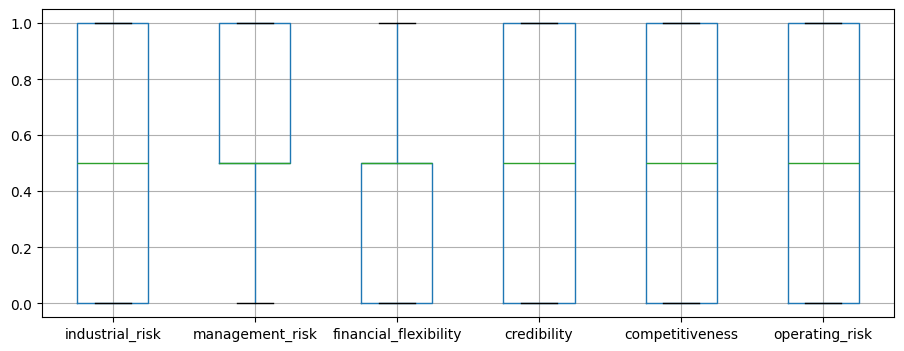

In [15]:
plt.figure(figsize=(11,4))
df.boxplot()
plt.show()

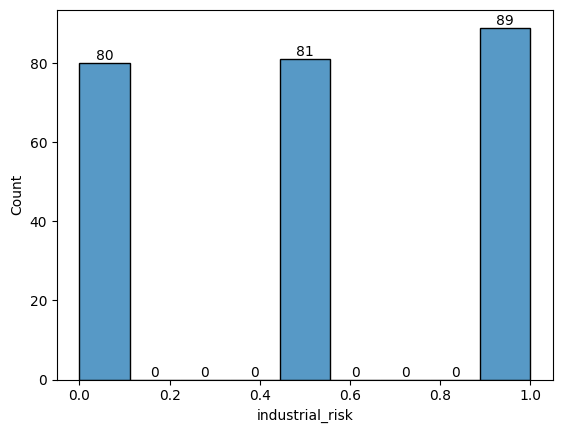

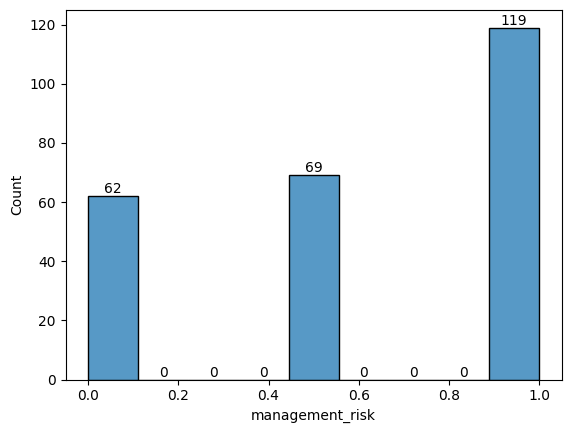

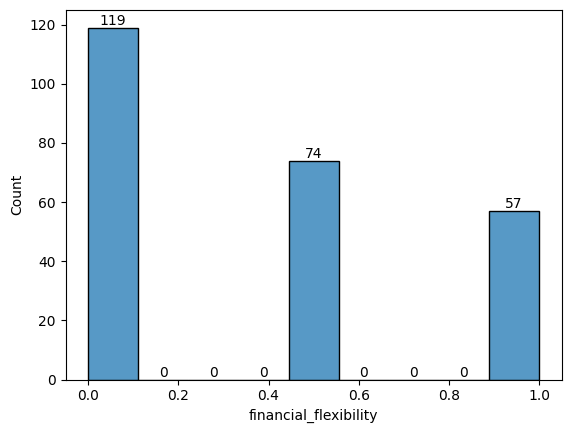

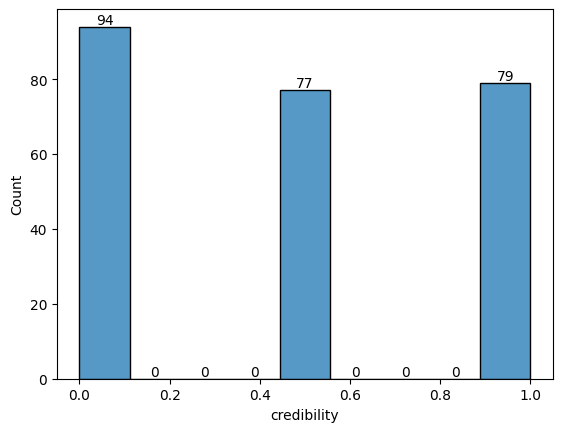

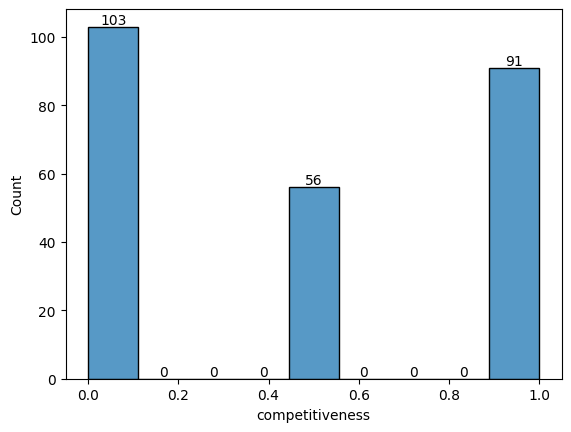

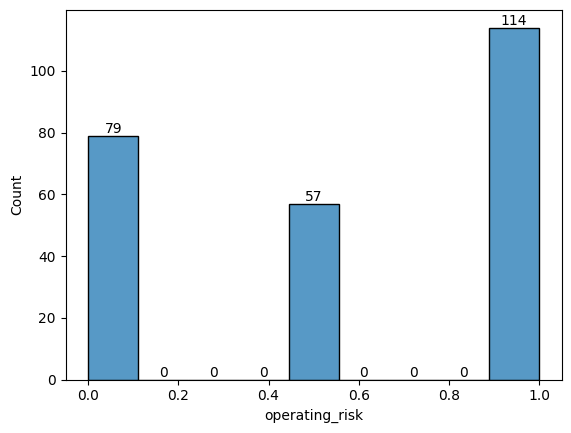

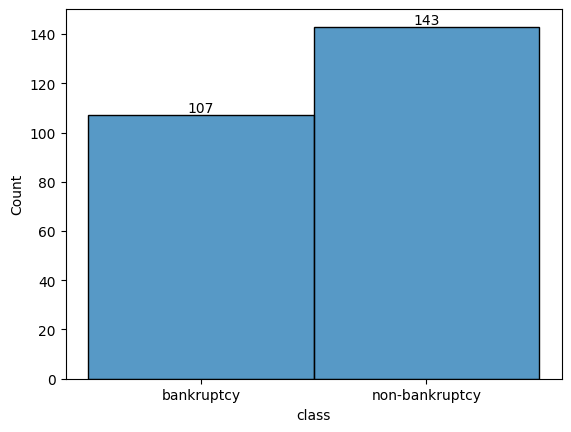

In [16]:
for i in df.columns:
    ax=sns.histplot(df,x=i)
    for c in ax.containers:
        ax.bar_label(c)
    plt.show()

In [17]:
df['class']=df['class'].map({'non-bankruptcy':0, 'bankruptcy':1})

In [18]:
df.loc[[3,140]]

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
3,0.5,0.0,0.0,0.5,0.0,1.0,1
140,1.0,0.0,0.5,1.0,0.5,0.0,0


In [19]:
cor=df.corr()
cor

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
industrial_risk,1.000000,0.255127,-0.162624,-0.014438,-0.257814,0.144507,0.227823
management_risk,0.255127,1.000000,-0.254845,-0.303341,-0.306568,0.213874,0.370838
financial_flexibility,-0.162624,-0.254845,1.000000,0.524951,0.686612,-0.116903,-0.751020
credibility,-0.014438,-0.303341,0.524951,1.000000,0.675689,-0.288458,-0.755909
competitiveness,-0.257814,-0.306568,0.686612,0.675689,1.000000,-0.211383,-0.899452
operating_risk,0.144507,0.213874,-0.116903,-0.288458,-0.211383,1.000000,0.279786
class,0.227823,0.370838,-0.751020,-0.755909,-0.899452,0.279786,1.000000


<Axes: >

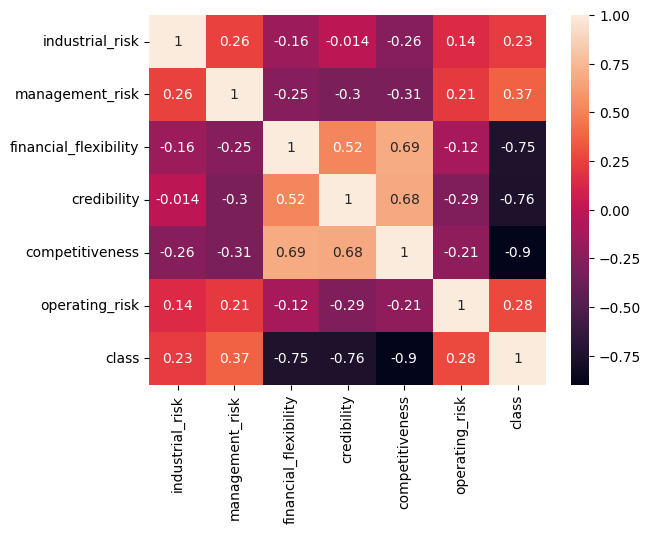

In [20]:
sns.heatmap(cor,annot=True)

**MODEL BUILDING**

In [21]:
features=df.drop(columns=['class'])
target=df['class']

In [22]:
features.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
0,0.5,1.0,0.0,0.0,0.0,0.5
1,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0
3,0.5,0.0,0.0,0.5,0.0,1.0
4,1.0,1.0,0.0,0.0,0.0,1.0


In [23]:
from sklearn.feature_selection import f_classif

In [24]:
fcls=f_classif(features,target)

In [25]:
pd.DataFrame(fcls[0],index=features.columns,columns=['score']).sort_values(by='score',ascending=False)

,score
competitiveness,1050.520973
credibility,330.625672
financial_flexibility,320.846947
management_risk,39.543195
operating_risk,21.062291
industrial_risk,13.576657


In [26]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [27]:
vif=pd.DataFrame()

In [28]:
vif['features']=features.columns

In [29]:
features_with_constant=features.copy()
features_with_constant['Intercept']=1

In [30]:
features_with_constant

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,Intercept
0,0.5,1.0,0.0,0.0,0.0,0.5,1
1,0.0,1.0,0.0,0.0,0.0,1.0,1
2,1.0,0.0,0.0,0.0,0.0,1.0,1
3,0.5,0.0,0.0,0.5,0.0,1.0,1
4,1.0,1.0,0.0,0.0,0.0,1.0,1
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,1
246,1.0,1.0,0.5,1.0,1.0,0.0,1
247,0.0,1.0,1.0,0.5,0.5,0.0,1
248,1.0,0.0,0.5,1.0,0.5,0.0,1


In [31]:
vif['VIF']=[
    variance_inflation_factor(features_with_constant.values,i)
    for i in range(len(features.columns))
]

In [32]:
vif=vif.sort_values(by="VIF",ascending=False)
print(vif)

                features       VIF
4        competitiveness  2.788219
3            credibility  2.128103
2  financial_flexibility  1.931439
0        industrial_risk  1.208550
1        management_risk  1.205396
5         operating_risk  1.134261


In [33]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import GroupShuffleSplit,cross_val_predict,StratifiedGroupKFold
from sklearn.metrics import confusion_matrix,classification_report,roc_auc_score

In [34]:
groups=features.astype(str).agg('|'.join,axis=1).factorize()[0]
gss=GroupShuffleSplit(n_splits=1,test_size=0.3,random_state=100)
train_idx,test_idx=next(gss.split(features,target,groups=groups))

In [35]:
x_train,x_test=features.iloc[train_idx],features.iloc[test_idx]
y_train,y_test=target.iloc[train_idx],target.iloc[test_idx]
groups_train=groups[train_idx]

In [36]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((184, 6), (66, 6), (184,), (66,))

In [37]:
x_train.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
0,0.5,1.0,0.0,0.0,0.0,0.5
1,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0
3,0.5,0.0,0.0,0.5,0.0,1.0
4,1.0,1.0,0.0,0.0,0.0,1.0


In [38]:
cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=100)

In [39]:
labels=['non-bankruptcy','bankruptcy']

**Logistic Regression**

In [40]:
from sklearn.linear_model import LogisticRegression

In [41]:
lr=LogisticRegression(C=0.5,max_iter=5000,solver='liblinear',random_state=42)

In [42]:
cv_pred=cross_val_predict(lr,x_train,y_train,cv=cv,groups=groups_train)

In [43]:
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.99      1.00      0.99        96
    bankruptcy       1.00      0.99      0.99        88

      accuracy                           0.99       184
     macro avg       0.99      0.99      0.99       184
  weighted avg       0.99      0.99      0.99       184



In [44]:
lr.fit(x_train,y_train)
pred_lr=lr.predict(x_test)
proba_lr=lr.predict_proba(x_test)[:,1]

In [45]:
print(classification_report(y_test,pred_lr,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



In [46]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay

In [47]:
#tesing logistic regression with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=lr.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

93.74%


**KNN**

In [48]:
from sklearn.neighbors import KNeighborsClassifier

In [49]:
knn=KNeighborsClassifier(n_neighbors=11,weights='distance',p=2)
cv_pred=cross_val_predict(knn,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.99      0.97      0.98        96
    bankruptcy       0.97      0.99      0.98        88

      accuracy                           0.98       184
     macro avg       0.98      0.98      0.98       184
  weighted avg       0.98      0.98      0.98       184



In [50]:
knn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=11, weights='distance')

In [51]:
pred_knn=knn.predict(x_test)
proba_knn=knn.predict_proba(x_test)[:,1]
print(classification_report(y_test,pred_knn,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



In [52]:
#tesing KNN with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=knn.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

100.00%


**SVC**

In [53]:
from sklearn.svm import SVC

In [54]:
svm=SVC(C=0.5,kernel='rbf',gamma='scale',probability=True,random_state=100)
cv_pred=cross_val_predict(svm,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.99      1.00      0.99        96
    bankruptcy       1.00      0.99      0.99        88

      accuracy                           0.99       184
     macro avg       0.99      0.99      0.99       184
  weighted avg       0.99      0.99      0.99       184



In [55]:
svm.fit(x_train,y_train)
pred_svm=svm.predict(x_test)
proba_svm=svm.predict_proba(x_test)[:,1]

In [56]:
print(classification_report(y_test,pred_svm,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



In [57]:
#tesing SVM with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=svm.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

99.69%


**Decision Tree**

In [58]:
from sklearn.tree import DecisionTreeClassifier

In [59]:
dt=DecisionTreeClassifier(max_depth=2,min_samples_split=10,min_samples_leaf=5,random_state=42)
cv_pred=cross_val_predict(dt,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.96      0.97      0.96        96
    bankruptcy       0.97      0.95      0.96        88

      accuracy                           0.96       184
     macro avg       0.96      0.96      0.96       184
  weighted avg       0.96      0.96      0.96       184



In [60]:
dt.fit(x_train,y_train)
pred_dt=dt.predict(x_test)
proba_dt=dt.predict_proba(x_test)[:,1]

In [61]:
print(classification_report(y_test,pred_dt,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      0.91      0.96        47
    bankruptcy       0.83      1.00      0.90        19

      accuracy                           0.94        66
     macro avg       0.91      0.96      0.93        66
  weighted avg       0.95      0.94      0.94        66



In [62]:
from sklearn.tree import plot_tree,export_text

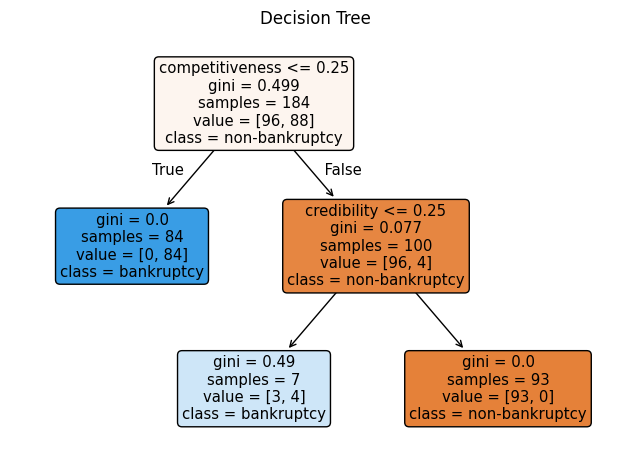

In [63]:
plot_tree(dt,feature_names=features.columns,class_names=labels,filled=True,rounded=True)
plt.title('Decision Tree')
plt.tight_layout()
plt.show()

In [64]:
#tesing Decision Tree with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=dt.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

100.00%


**Random Forest**

In [65]:
from sklearn.ensemble import RandomForestClassifier

In [66]:
rf=RandomForestClassifier(n_estimators=100,max_depth=3,min_samples_split=10,min_samples_leaf=5,max_features='sqrt',random_state=42)

In [67]:
cv_pred=cross_val_predict(rf,x_train,y_train,cv=cv,groups=groups_train)
print(classification_report(y_train,cv_pred,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       0.96      0.99      0.97        96
    bankruptcy       0.99      0.95      0.97        88

      accuracy                           0.97       184
     macro avg       0.97      0.97      0.97       184
  weighted avg       0.97      0.97      0.97       184



In [68]:
rf.fit(x_train,y_train)
pred_rf=rf.predict(x_test)
proba_rf=rf.predict_proba(x_test)[:,1]

In [69]:
print(classification_report(y_test,pred_rf,target_names=labels))

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



In [70]:
#tesing Random Forest with an ip
ip=[1,0.5,0,0,0,1]
new=pd.DataFrame([ip],columns=features.columns)
p=rf.predict_proba(new)[0][1]
print(f'{p*100:.2f}%')

98.79%


### **XGBoost Classifier**

In [71]:
from xgboost import XGBClassifier

In [72]:
xgb = XGBClassifier( n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=2,
    random_state=100,
    eval_metric='logloss')

In [73]:
cv_pred_xgb = cross_val_predict(xgb, x_train, y_train, cv=cv, groups=groups_train)
print("--- XGBoost Cross-Validation Report (Train Set) ---")
print(classification_report(y_train, cv_pred_xgb, target_names=labels))

--- XGBoost Cross-Validation Report (Train Set) ---
                precision    recall  f1-score   support

non-bankruptcy       0.96      0.99      0.97        96
    bankruptcy       0.99      0.95      0.97        88

      accuracy                           0.97       184
     macro avg       0.97      0.97      0.97       184
  weighted avg       0.97      0.97      0.97       184



In [74]:
# Fit XGBoost model on full training set and evaluate on test set
xgb.fit(x_train, y_train)
pred_xgb = xgb.predict(x_test)
proba_xgb = xgb.predict_proba(x_test)[:, 1]

print("--- XGBoost Performance Report (Test Set) ---")
print(classification_report(y_test, pred_xgb, target_names=labels))

--- XGBoost Performance Report (Test Set) ---
                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        47
    bankruptcy       1.00      1.00      1.00        19

      accuracy                           1.00        66
     macro avg       1.00      1.00      1.00        66
  weighted avg       1.00      1.00      1.00        66



In [75]:
# Create a dictionary to hold predictions
models = {
    'Logistic Regression': lr,
    'KNN': knn,
    'SVM': svm,
    'Decision Tree': dt,
    'Random Forest': rf,
    'XGBoost': xgb
}


In [76]:
plt.figure(figsize=(10, 8))

# Plot ROC curve for each model
for name, model in models.items():
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(x_test)[:, 1]
    else:
        proba = model.decision_function(x_test)

    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})', lw=2)

# Plot random guess line
plt.plot([0, 1], [0, 1], '--', color='grey', label='Random Guess')

plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curves Comparison (All Models)', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

NameError: name 'roc_curve' is not defined

<Figure size 1000x800 with 0 Axes>

In [77]:
from sklearn.metrics import precision_recall_curve,average_precision_score,cohen_kappa_score,matthews_corrcoef,roc_curve,auc

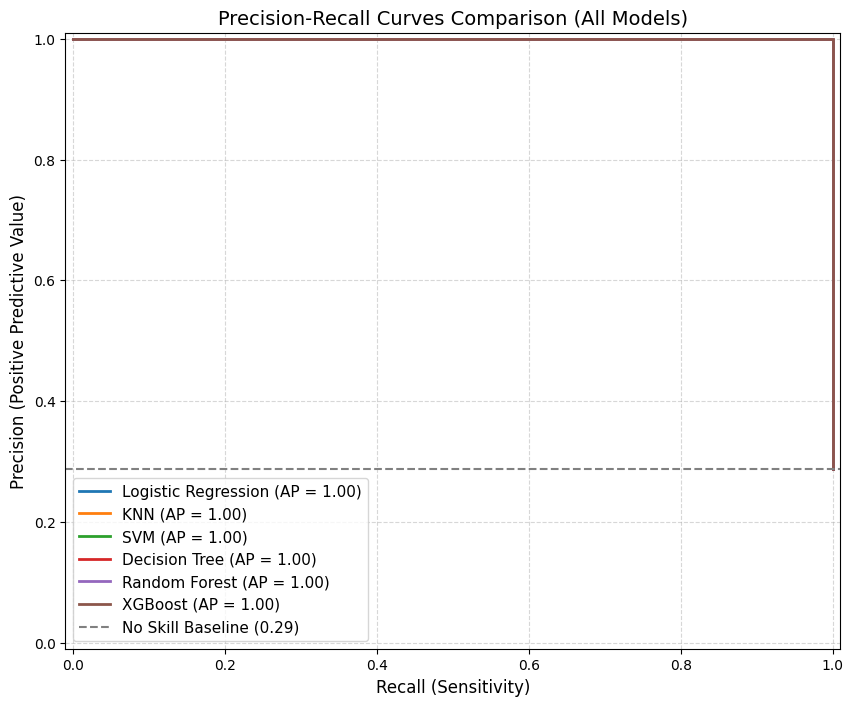

In [78]:
metrics_summary=[]

plt.figure(figsize=(10,8))

for name,model in models.items():
    if hasattr(model,'predict_proba'):
        proba=model.predict_proba(x_test)[:,1]
    else:
        proba=model.decision_function(x_test)
    preds = model.predict(x_test)

    # Calculate Precision-Recall Curve
    precision,recall,_ = precision_recall_curve(y_test,proba)
    ap=average_precision_score(y_test,proba)

    # Calculate Cohen's Kappa and MCC
    kappa=cohen_kappa_score(y_test,preds)
    mcc=matthews_corrcoef(y_test,preds)

    # Store metrics
    metrics_summary.append({
        'Model':name,
        'Average Precision (AP)':round(ap,3),
        "Cohen's Kappa":round(kappa,3),
        "Matthews Corr Coef (MCC)":round(mcc,3)
    })

    # Plot PR Curve
    plt.plot(recall,precision,label=f'{name} (AP = {ap:.2f})',lw=2)

# Plot no-skill line (proportion of positive class in test set)
no_skill=len(y_test[y_test==1]) / len(y_test)
plt.axhline(y=no_skill,color='grey',linestyle='--',label=f'No Skill Baseline ({no_skill:.2f})')

plt.xlim([-0.01,1.01])
plt.ylim([-0.01,1.01])
plt.xlabel('Recall (Sensitivity)',fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)',fontsize=12)
plt.title('Precision-Recall Curves Comparison (All Models)',fontsize=14)
plt.legend(loc='lower left',fontsize=11)
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

In [79]:
df_metrics=pd.DataFrame(metrics_summary)
display(df_metrics)

,Model,Average Precision (AP),Cohen's Kappa,Matthews Corr Coef (MCC)
0,Logistic Regression,1.0,1.000,1.000
1,KNN,1.0,1.000,1.000
2,SVM,1.0,1.000,1.000
3,Decision Tree,1.0,0.861,0.869
4,Random Forest,1.0,1.000,1.000
5,XGBoost,1.0,1.000,1.000


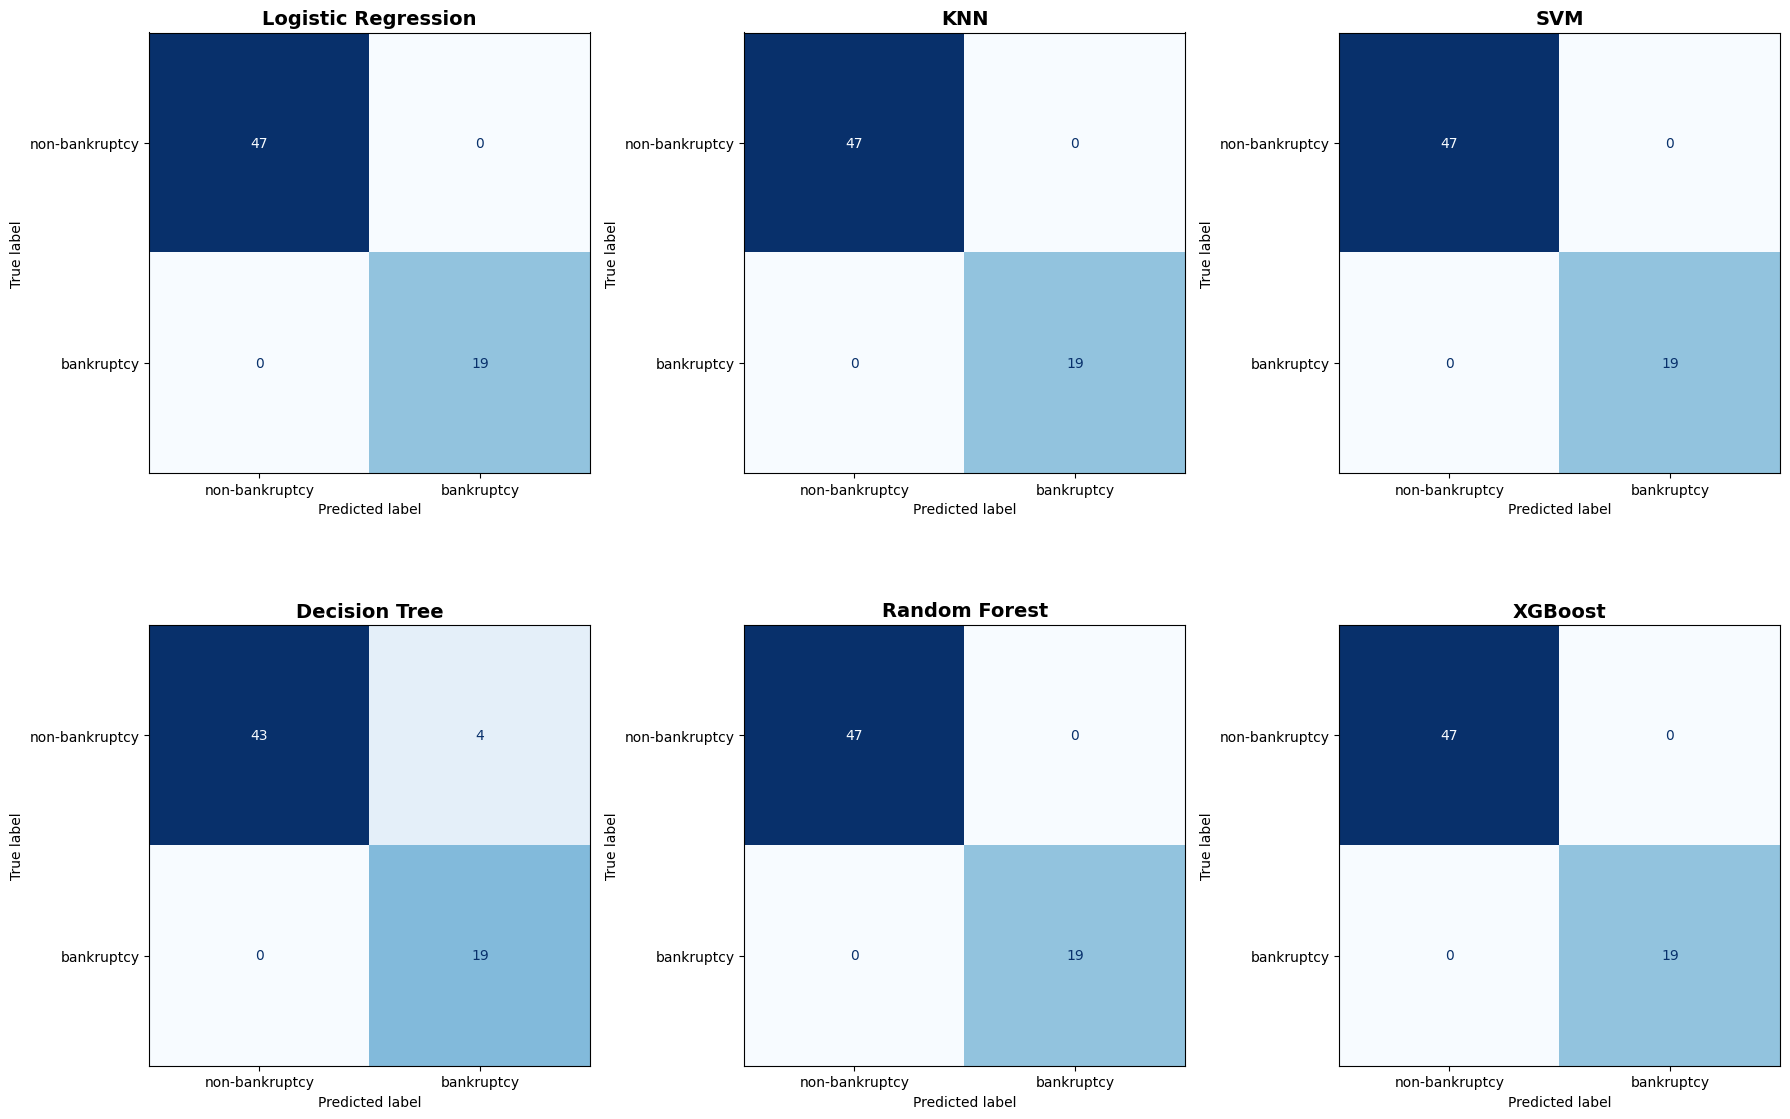

In [80]:
fig,axes=plt.subplots(nrows=2,ncols=3,figsize=(18,12))
axes=axes.flatten()

for idx,(name,model) in enumerate(models.items()):
    disp=ConfusionMatrixDisplay.from_estimator(
        model,
        x_test,
        y_test,
        display_labels=labels,
        ax=axes[idx],
        cmap='Blues',
        colorbar=False
    )
    axes[idx].set_title(f'{name}',fontsize=14,fontweight='bold')
    axes[idx].grid(False)

plt.tight_layout()
plt.show()

In [84]:
import joblib

joblib.dump(lr,'final_bankruptcy_model.pkl')

['final_bankruptcy_model.pkl']

In [85]:
loaded_model=joblib.load('final_bankruptcy_model.pkl')

sample_ip=[1.0,0.5,0.0,0.0,0.0,1.0]
test_df=pd.DataFrame([sample_ip],columns=features.columns)

pred_proba = loaded_model.predict_proba(test_df)[0][1]

print(f"Bankruptcy Probability Risk: {pred_proba * 100:.2f}%")

Bankruptcy Probability Risk: 93.74%
